Spotify Dataset - Machine Learning

Lucas Concha
Natalia Hormazabal
Martin Villarroel

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler



df = pd.read_csv('../data/Spotify_Tracks_Dataset.csv')
print(f"Filas y Columnas iniciales: {df.shape}")
df.head()

Filas y Columnas iniciales: (114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## Inspección


In [2]:
df.info()
df.isna().sum()[df.isna().sum() > 0]

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

artists       1
album_name    1
track_name    1
dtype: int64

## Eliminación de variables no predictivas 


In [3]:
df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")])
df.shape

(114000, 20)

## Valores nulos


In [4]:
df = df.dropna(subset=["artists", "album_name", "track_name"])
df.shape

(113999, 20)

## Duplicados 

In [5]:
print("Duplicados exactos:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape tras eliminar duplicados exactos:", df.shape)

Duplicados exactos: 450
Shape tras eliminar duplicados exactos: (113549, 20)


In [6]:
rep = df["track_id"].duplicated(keep=False).sum()
print(f"Filas con track_id repetido en distintos generos: {rep} ({rep/len(df)*100:.1f}%)")


Filas con track_id repetido en distintos generos: 40108 (35.3%)


In [7]:
print("Canciones únicas (track_id distintos):", df["track_id"].nunique())
repetidas = df[df["track_id"].duplicated(keep=False)]
rango_pop = repetidas.groupby("track_id")["popularity"].agg(lambda s: s.max() - s.min())
print(f"% de track_id repetidos con la misma popularity en todos sus géneros: {(rango_pop == 0).mean()*100:.1f}%")

Canciones únicas (track_id distintos): 89740
% de track_id repetidos con la misma popularity en todos sus géneros: 95.6%


Una canción repetida en varios géneros conserva casi siempre la misma `popularity`. Al modelar hay que particionar agrupando por `track_id` (GroupKFold); si no, la misma canción cae en train y en test (fuga de información).

## Outliers

In [8]:
print("Canciones con duration_ms == 0:", (df["duration_ms"] == 0).sum())
print("Canciones con tempo == 0:", (df["tempo"] == 0).sum())

Canciones con duration_ms == 0: 0
Canciones con tempo == 0: 157


In [9]:
q1, q3 = df["duration_ms"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 3 * iqr
extreme = df[df["duration_ms"] > upper]
print(f"Umbral outlier extremo (Q3 + 3*IQR): {upper/60000:.1f} min")
print(f"Canciones sobre el umbral: {len(extreme)} ({len(extreme)/len(df)*100:.2f}%)")

tempo_zero = df[df["tempo"] == 0].copy()
tempo_zero["anomalia"] = "tempo_cero"
dur_extreme = extreme.copy()
dur_extreme["anomalia"] = "duracion_extrema"
anomalias = pd.concat([tempo_zero, dur_extreme]).drop_duplicates(subset=["track_id", "anomalia"])
anomalias.to_csv("../data_procesado/spotify_tracks_anomalias.csv", index=False)
print("Anomalias exportadas:", anomalias.shape)


Umbral outlier extremo (Q3 + 3*IQR): 8.7 min
Canciones sobre el umbral: 1217 (1.07%)
Anomalias exportadas: (1256, 21)


In [10]:
df["time_signature"].value_counts().sort_index()

time_signature
0       163
1       967
3      9128
4    101486
5      1805
Name: count, dtype: int64

**Decisión sobre las anomalías:** se documentan en `spotify_tracks_anomalias.csv` y se **conservan** en el dataset limpio (~1,1% de los datos; las duraciones largas pueden ser legítimas). En el modelado se comparará el error con y sin ellas.

- 1.217 filas superan el umbral de duración, pero el archivo registra 1.099 de ese tipo porque se deduplica por `track_id` (1.099 + 157 de `tempo_cero` = 1.256).
- `time_signature = 0` (163 filas) probablemente es dato faltante; se deja como observación.

## Análisis por género

In [11]:
por_genero = (df.groupby("track_genre")["popularity"]
                .agg(media="mean", mediana="median", n="count",
                     pct_ceros=lambda s: (s == 0).mean() * 100)
                .sort_values("media", ascending=False))

print(f"Géneros: {len(por_genero)} | canciones por género: mín {por_genero['n'].min()}, máx {por_genero['n'].max()}")
print("\n6 géneros más populares:")
print(por_genero.head(6).round(1).to_string())
print("\n6 géneros menos populares:")
print(por_genero.tail(6).round(1).to_string())
print("\nGéneros con mayor % de popularity = 0:")
print(por_genero.sort_values("pct_ceros", ascending=False).head(6)[["media", "pct_ceros"]].round(1).to_string())

def eta_cuadrado(datos):
    # proporción de la varianza de popularity explicada solo por el género
    media = datos["popularity"].mean()
    ss_entre = sum(len(g) * (g["popularity"].mean() - media) ** 2
                   for _, g in datos.groupby("track_genre"))
    ss_total = ((datos["popularity"] - media) ** 2).sum()
    return ss_entre / ss_total

print(f"\nη² género -> popularity: {eta_cuadrado(df):.3f}")
print(f"η² excluyendo popularity = 0: {eta_cuadrado(df[df['popularity'] > 0]):.3f}")

Géneros: 114 | canciones por género: mín 904, máx 1000

6 géneros más populares:
             media  mediana     n  pct_ceros
track_genre                                 
pop-film      59.3     60.0   999        0.2
k-pop         57.0     60.0   998        3.8
chill         53.7     57.0   999        3.9
sad           52.4     54.0  1000        1.4
grunge        49.6     55.0   999        3.8
indian        49.5     49.0   999        1.2

6 géneros menos populares:
                media  mediana    n  pct_ceros
track_genre                                   
classical        13.5      3.0  933       40.9
chicago-house    12.3     10.0  998        0.4
detroit-techno   11.2      8.0  998        0.1
latin             8.4      0.0  990       59.1
romance           3.5      0.0  904       61.4
iranian           2.2      0.0  988       65.6

Géneros con mayor % de popularity = 0:
             media  pct_ceros
track_genre                  
jazz          13.6       68.2
iranian        2.2       

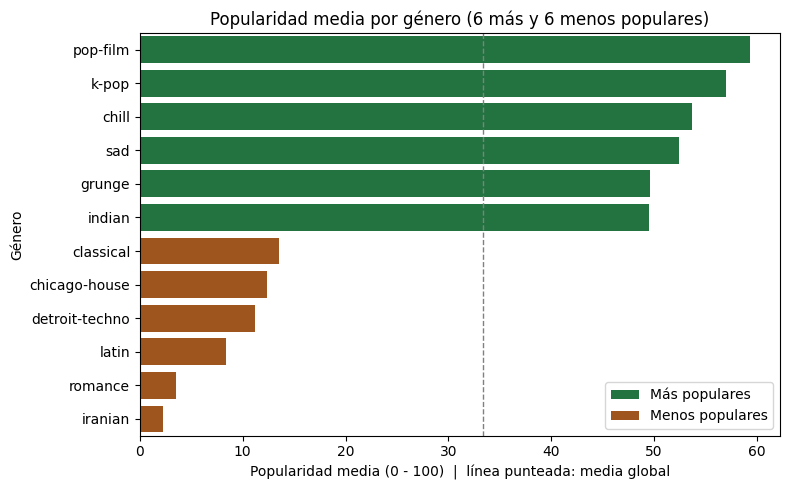

In [12]:
seleccion = pd.concat([por_genero.head(6).assign(grupo="Más populares"),
                       por_genero.tail(6).assign(grupo="Menos populares")]).reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=seleccion, x="media", y="track_genre", hue="grupo", dodge=False,
            palette={"Más populares": "#15803D", "Menos populares": "#B45309"})
plt.axvline(df["popularity"].mean(), color="gray", linestyle="--", linewidth=1)
plt.title("Popularidad media por género (6 más y 6 menos populares)")
plt.xlabel("Popularidad media (0 - 100)  |  línea punteada: media global")
plt.ylabel("Género")
plt.legend(title=None)
plt.tight_layout()
plt.savefig('../images/popularidad_por_genero.png')
plt.show()

El género explica ~25% de la varianza de `popularity` (η² = 0,25; ~38% sin los ceros), mucho más que cualquier variable de audio. Los ceros se concentran en ciertos géneros (más del 60% en `jazz`, `iranian`, `romance` y `soul`), así que parte de la diferencia entre géneros puede venir de cómo se asigna la popularidad. Cada género tiene entre 904 y 1.000 canciones: el dataset está equilibrado por construcción y no refleja el peso real de cada género en Spotify.

## Variables categóricas 

- explicit se convierte a entero 
- Track_genre one hot encoding (para modelar)
- key, mode, time_signature se mantienen como enteros 


In [13]:
df["explicit"] = df["explicit"].astype(int)

genre_dummies = pd.get_dummies(df["track_genre"], prefix="genre", drop_first=True).astype(int)
df = pd.concat([df.drop(columns=["track_genre"]), genre_dummies], axis=1)
print("Dummies de genero generadas:", genre_dummies.shape[1])
df.head()


Dummies de genero generadas: 113


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,...,genre_spanish,genre_study,genre_swedish,genre_synth-pop,genre_tango,genre_techno,genre_trance,genre_trip-hop,genre_turkish,genre_world-music
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,0,0.676,0.4610,1,...,0,0,0,0,0,0,0,0,0,0
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,0,0.420,0.1660,1,...,0,0,0,0,0,0,0,0,0,0
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,0,0.438,0.3590,0,...,0,0,0,0,0,0,0,0,0,0
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,0,0.266,0.0596,0,...,0,0,0,0,0,0,0,0,0,0
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,0,0.618,0.4430,2,...,0,0,0,0,0,0,0,0,0,0


## Escalado

In [14]:
audio_cols = ["danceability", "energy", "loudness", "speechiness",
              "acousticness", "instrumentalness", "liveness", "valence", "tempo"]

scaler = MinMaxScaler()
df[audio_cols] = scaler.fit_transform(df[audio_cols])
df[audio_cols].describe().loc[["min", "max"]]


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


El escalador se ajusta aquí con todo el dataset. En el modelado debe ajustarse solo con el conjunto de entrenamiento (evita fuga de información). `duration_ms` no se escala en esta etapa (no es un atributo de audio; depende del modelo).

## Selección de características

In [15]:
# VIF de cada variable de audio (diagonal de la inversa de la matriz de correlación)
corr_audio = df[audio_cols].corr()
vif = pd.Series(np.diag(np.linalg.inv(corr_audio.values)), index=audio_cols, name="VIF").round(2)
print(vif.sort_values(ascending=False).to_string())

pares = [(a, b, round(corr_audio.loc[a, b], 2))
         for i, a in enumerate(audio_cols) for b in audio_cols[i + 1:]
         if abs(corr_audio.loc[a, b]) > 0.7]
print("\nPares con |r| > 0,7:", pares)

energy              4.22
loudness            3.26
acousticness        2.39
valence             1.55
danceability        1.49
instrumentalness    1.45
liveness            1.14
speechiness         1.12
tempo               1.09

Pares con |r| > 0,7: [('energy', 'loudness', np.float64(0.76)), ('energy', 'acousticness', np.float64(-0.73))]


In [16]:
TARGET = "popularity"
COL_ID = "track_id"                                    # solo para agrupar la partición
COLS_TEXTO = ["artists", "album_name", "track_name"]   # texto: no son predictoras
COLS_GENERO = [c for c in df.columns if c.startswith("genre_")]
FEATURES = audio_cols + ["duration_ms", "explicit", "key", "mode", "time_signature"] + COLS_GENERO

print(f"Predictoras seleccionadas: {len(FEATURES)} ({len(audio_cols)} de audio + 5 discretas/metadatos + {len(COLS_GENERO)} dummies de género)")

Predictoras seleccionadas: 127 (9 de audio + 5 discretas/metadatos + 113 dummies de género)


- Se excluyen como predictoras `track_id` (solo para agrupar la partición) y `artists`, `album_name`, `track_name` (texto de alta cardinalidad). Se mantienen en el CSV por trazabilidad.
- Multicolinealidad moderada: VIF máximo 4,2 (`energy`, correlacionada con `loudness` y `acousticness`), bajo el umbral de 5. No se elimina ninguna variable de audio.
- Se mantienen las dummies de género (la señal más fuerte).
- **Selección final:** 127 variables predictoras (9 de audio + 5 discretas/metadatos + 113 dummies de género). Ninguna cumple un criterio de exclusión (VIF > 5 o ser identificador/texto), por lo que se conservan todas.

In [17]:
assert df.isna().sum().sum() == 0, "Hay valores nulos"
assert not df.duplicated().any(), "Hay duplicados exactos"
assert df[audio_cols].min().min() >= 0 and df[audio_cols].max().max() <= 1, "Audio fuera de [0, 1]"
assert set(FEATURES + COLS_TEXTO + [COL_ID, TARGET]) == set(df.columns), "Columnas sin clasificar"
print("Validaciones OK")

Validaciones OK


In [18]:
df.to_csv("../data_procesado/spotify_tracks_clean.csv", index=False)
print("Shape final exportado:", df.shape)


Shape final exportado: (113549, 132)


## Visualizaciones

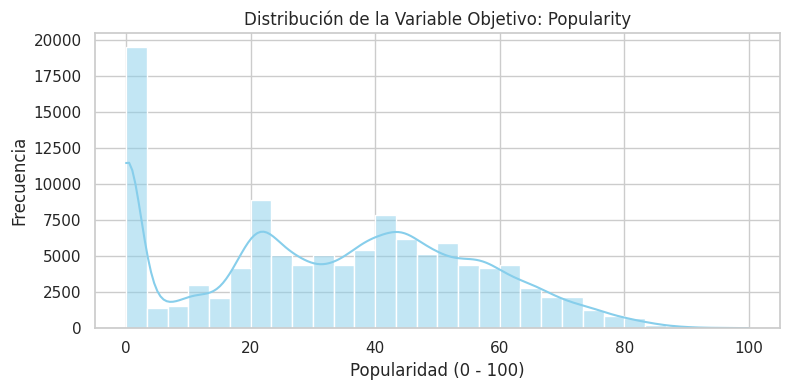

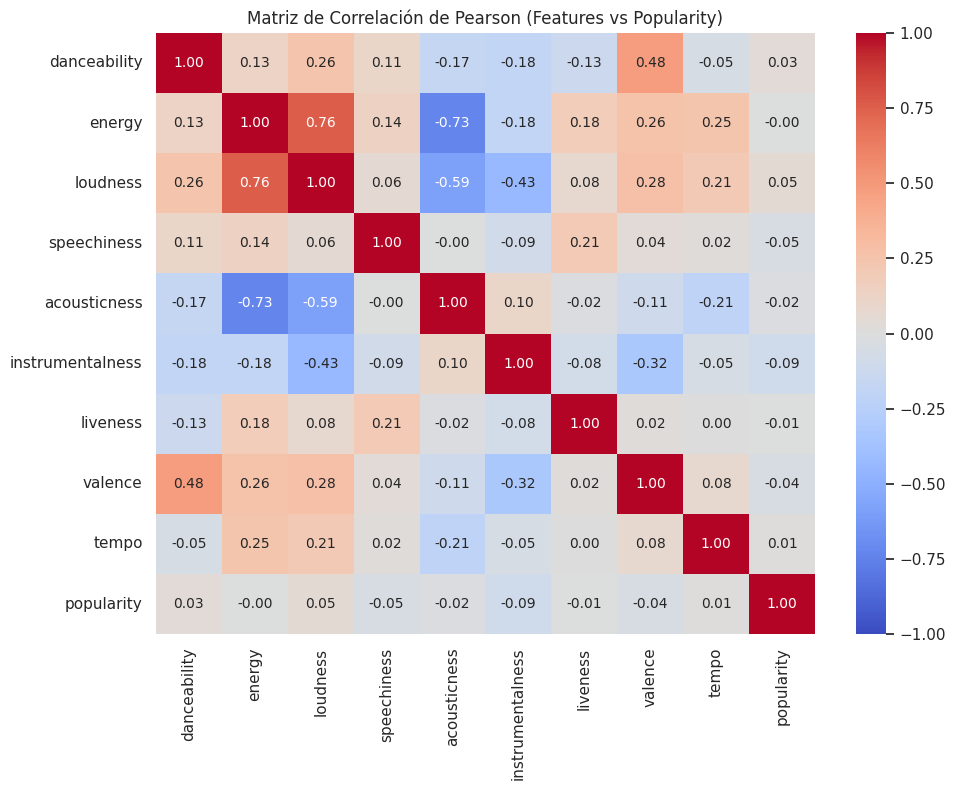

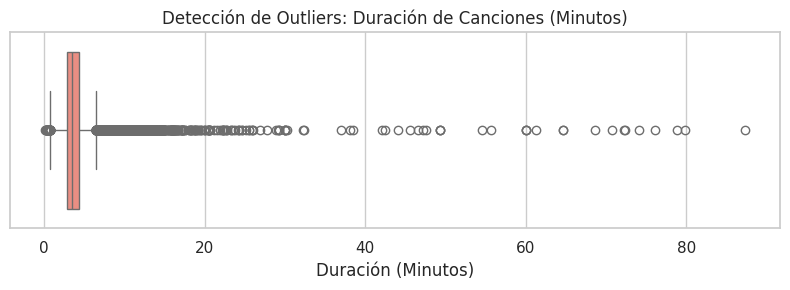

In [19]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10})

# 1. Distribución de la variable objetivo (Popularity)
plt.figure(figsize=(8, 4))
sns.histplot(df['popularity'], kde=True, bins=30, color='skyblue')
plt.title('Distribución de la Variable Objetivo: Popularity')
plt.xlabel('Popularidad (0 - 100)')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.savefig('../images/distribucion_popularity.png')
plt.show()

# 2. Matriz de Correlación entre características de Audio y Popularity
corr_cols = ["danceability", "energy", "loudness", "speechiness",
             "acousticness", "instrumentalness", "liveness", "valence", "tempo", "popularity"]

plt.figure(figsize=(10, 8))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title('Matriz de Correlación de Pearson (Features vs Popularity)')
plt.tight_layout()
plt.savefig('../images/matriz_correlacion.png')
plt.show()

# 3. Boxplot de Detección de Outliers en Duration (Minutos)
plt.figure(figsize=(8, 3))
sns.boxplot(x=df['duration_ms'] / 60000, color='salmon')
plt.title('Detección de Outliers: Duración de Canciones (Minutos)')
plt.xlabel('Duración (Minutos)')
plt.tight_layout()
plt.savefig('../images/boxplot_duration.png')
plt.show()

In [20]:
ceros = (df["popularity"] == 0).sum()
hits = (df["popularity"] > 70).sum()
print(f"Media: {df['popularity'].mean():.1f} | mediana: {df['popularity'].median():.0f}")
print(f"popularity == 0: {ceros} canciones ({ceros/len(df)*100:.1f}%)")
print(f"popularity > 70 (hits): {hits} canciones ({hits/len(df)*100:.1f}%)")

num_cols = audio_cols + ["duration_ms", "explicit", "key", "mode", "time_signature"]
ranking = pd.DataFrame({
    "pearson": df[num_cols + ["popularity"]].corr()["popularity"],
    "spearman": df[num_cols + ["popularity"]].corr(method="spearman")["popularity"],
}).drop("popularity")
ranking = ranking.reindex(ranking["pearson"].abs().sort_values(ascending=False).index).round(3)
print("\nCorrelación con popularity:")
print(ranking.to_string())

Media: 33.3 | mediana: 35
popularity == 0: 15843 canciones (14.0%)
popularity > 70 (hits): 4843 canciones (4.3%)

Correlación con popularity:
                  pearson  spearman
instrumentalness   -0.095    -0.078
loudness            0.047     0.033
speechiness        -0.045    -0.068
explicit            0.044     0.040
valence            -0.041    -0.042
danceability        0.034     0.026
time_signature      0.031     0.036
acousticness       -0.022     0.011
mode               -0.015    -0.016
tempo               0.012     0.016
duration_ms        -0.008     0.027
liveness           -0.006    -0.008
key                -0.004    -0.003
energy             -0.002    -0.027


- `popularity` no es normal: pico en 0 (~14% de las canciones) y solo 4,3% de hits (> 70).
- Ninguna variable de audio supera |r| = 0,10 con `popularity` (la mayor es `instrumentalness`, −0,09; Spearman también ≤ 0,08). Solo `energy`–`loudness` (0,76) y `energy`–`acousticness` (−0,73) están fuertemente correlacionadas entre sí.
- La cola de duración llega a ~87 min (asimetría 10,8), lo que justifica el umbral Q3 + 3×IQR.

## Conclusiones y próximos pasos

- Dataset limpio: 113.549 filas × 132 columnas, sin nulos ni duplicados exactos; 1.256 anomalías documentadas y conservadas.
- Los atributos de audio explican muy poco de `popularity`; el género es la señal más fuerte (η² = 0,25).
- Riesgos para el modelado: ~14% de ceros, solo 4,3% de hits y canciones repetidas por género (35,3% de las filas).
- Modelado: partición agrupada por `track_id`, escalador ajustado solo con train, modelo base (RMSE / MAE), modelos no lineales, Hit Recall y error por género.